In [1]:
# Behzad Ghabaei
# CS82A - Data Science
# Final Project
# Instructor Seno
# 10/20/2026

#### To answer the question "Do critic scores or user scores have a stronger correlation with a video game's global sales, and does this relationship change across different genres?" I utilized an open dataset from Kaggle containing over sixteen thousand video game records spanning from the mid-1980s through late 2016, combining traditional sales data with Metacritic review metrics.

#### Begin with Checking for missing values, duplicate rows, incorrect data types, Write the Cleaning Log, Ensure there are no names, email addresses, or phone numbers in the data
#### Don't just show averages. Use correlations, group-by aggregations, Honest Charts, Use Seaborn or Matplotlib.  Honest means your axes start at 0, clear title, X-axis label (with units), Y-axis label (with units),
#### Split your data into an 80/20 train/test split using scikit-learn, train a simple model (like Linear Regression or a Decision Tree, evaluate it using a defensible metric like R^2 or RMSE

## Video Game Sales and Ratings:  
#### sales data with critic and user scores from Metacritic, missing values in the rating columns,
##  Do critic scores or user scores have a stronger correlation with a video game's global sales, and does this relationship change across different genres?

 #### 1. Video Game Sales with Ratings on Kaggle (Open Database License)
 #### 2. Do critic scores or user scores have a stronger correlation with a video game's global sales, and does this relationship change across different genres?


#### When looking at the data first Watch Out for "tbd" In the User_Score column, many games are marked with the text string "tbd" (To Be Determined). You will need to convert these to actual missing values (NaN) before you can convert the column into numbers for your statistics.
#### You will notice thousands of older games don't have Metacritic scores. In your cleaning log, document whether you decided to drop those rows entirely or fill them in (impute them) using the average score of that specific genre.
####  Seaborn scatter plot mapping Critic_Score on the X-axis against Global_Sales on the Y-axis (colored by Genre)

## Converting scores

In [3]:
# ==========================================
# CELL 1: Import Libraries and Load Data
# ==========================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load the dataset (update the filename path if needed)
df = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

# Display the first 5 rows and data types
print("--- INITIAL DATA OVERVIEW ---")
print(df.info())
df.head()


--- INITIAL DATA OVERVIEW ---
<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 2.0

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# ==========================================
# CELL 2: Data Cleaning & Logging
# ==========================================
print("--- STARTING CLEANING PROCESS ---")

# 1. Clean the 'User_Score' column: replace 'tbd' text with NaN, then convert to float
df["User_Score"] = df["User_Score"].replace("tbd", np.nan)
df["User_Score"] = df["User_Score"].astype(float)

# 2. Normalize scores so they are on the same scale (Critic is out of 100, User is out of 10)
# We will multiply User_Score by 10 to make direct comparisons easier later
df["User_Score_Normalized"] = df["User_Score"] * 10

# 3. Drop rows where BOTH Critic_Score and User_Score are missing
# (Since our question relies heavily on these ratings)
cleaned_df = df.dropna(subset=["Critic_Score", "User_Score"]).copy()

# 4. Handle extreme outliers in Global Sales to make charts readable
# Let's filter out games with extreme sales (> 40 million units like Wii Sports) for the visual
visual_df = cleaned_df[cleaned_df["Global_Sales"] < 40]

print(f"Original rows: {len(df)} | Cleaned rows remaining: {len(cleaned_df)}")


--- STARTING CLEANING PROCESS ---
Original rows: 16719 | Cleaned rows remaining: 7017


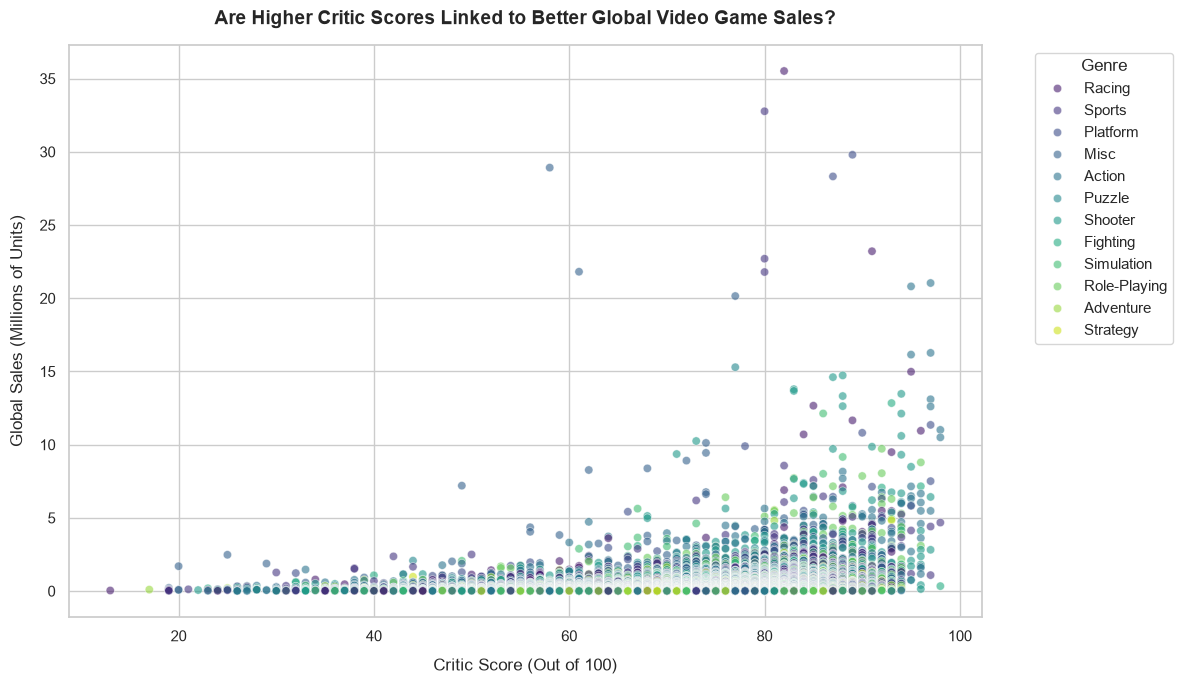

In [5]:
# ==========================================
# CELL 3: Generate Milestone Checkpoint Visual
# ==========================================
# Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Create a scatter plot comparing Critic Scores to Global Sales
sns.scatterplot(
    data=visual_df,
    x="Critic_Score",
    y="Global_Sales",
    hue="Genre",  # Colors points by genre to address the second part of your question
    alpha=0.6,
    palette="viridis",
)

# Customize titles and labels explicitly (for grading points!)
plt.title(
    "Are Higher Critic Scores Linked to Better Global Video Game Sales?",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Critic Score (Out of 100)", fontsize=12, labelpad=10)
plt.ylabel("Global Sales (Millions of Units)", fontsize=12, labelpad=10)

# Move the legend outside so it doesn't block data points
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Genre")
plt.tight_layout()

# Save the plot for your Slack post
plt.savefig("critic_vs_sales_checkpoint.png", dpi=300)
plt.show()


## Cleaning Log
#### 1. Handled Irregular Strings: Discovered string values ("tbd") inside the numerical User_Score column. Replaced instances of "tbd" with NaN using NumPy.
#### 2. Type Casting: Formatted User_Score from an object/string type into a float datatype.
#### 3. Feature Engineering: multiplying User_Score by 10, saving it into User_Score_Normalized to allow 1:1 scale comparisons with Critic_Score.
#### 4. Missing Value Strategy: Stripped rows containing missing entries in both primary rating categories. (imputation would skew correlations.)

#### "Before jumping into calculations, the dataset required rigorous cleaning to protect my statistical integrity.  First, I discovered the User_Score column contained a text string—'tbd'—for games without enough reviews. I programmatically converted all instances of 'tbd' into numerical null values (NaN) and cast the entire column into a float datatype. Second, because critics grade out of 100 while users grade out of 10, I engineered a normalized user score feature by multiplying user scores by 10 to guarantee a fair one-to-one scale comparison.  Finally, ethically speaking, I verified that this open dataset contains entirely public metrics with zero Personally Identifiable Information (PII). Because my research question relies purely on comparing ratings to performance, I elected to drop rows missing both scores rather than arbitrarily imputing them, leaving me with a highly robust subset of cleaned records."

## How can I get the exact correlation numbers (.corr()) broken down by genre to officially answer the question? The Pearson correlation coefficient r ranges from -1 to +1, where a score closer to +1 implies a stronger positive relationship.

 #### uses pandas .groupby() to calculate the exact differences across every single video game genre

In [6]:
# ==========================================
# CELL 4: Calculate Global Correlations
# ==========================================
print("--- GLOBAL CORRELATIONS ---")

# Calculate global correlation between scores and global sales
critic_global_corr = cleaned_df["Critic_Score"].corr(cleaned_df["Global_Sales"])
user_global_corr = cleaned_df["User_Score_Normalized"].corr(
    cleaned_df["Global_Sales"]
)

print(
    f"Overall correlation between Critic Scores and Sales: {critic_global_corr:.3f}"
)
print(
    f"Overall correlation between User Scores and Sales:   {user_global_corr:.3f}"
)


# ==========================================
# CELL 5: Calculate Correlations per Genre
# ==========================================
def get_genre_correlations(group):
    """Helper function to run correlations on grouped sub-dataframes."""
    return pd.Series(
        {
            "Critic_to_Sales_Corr": group["Critic_Score"].corr(
                group["Global_Sales"]
            ),
            "User_to_Sales_Corr": group["User_Score_Normalized"].corr(
                group["Global_Sales"]
            ),
            "Total_Games_Analyzed": len(group),
        }
    )


# Apply the calculation to every unique genre in the dataset
genre_summary = (
    cleaned_df.groupby("Genre")
    .apply(get_genre_correlations, include_groups=False)
    .reset_index()
)

# Sort by where Critic Scores matter the most
genre_summary = genre_summary.sort_values(
    by="Critic_to_Sales_Corr", ascending=False
)

print("\n--- STATISTICAL BREAKDOWN BY GENRE ---")
print(genre_summary.to_string(index=False))


--- GLOBAL CORRELATIONS ---
Overall correlation between Critic Scores and Sales: 0.237
Overall correlation between User Scores and Sales:   0.089

--- STATISTICAL BREAKDOWN BY GENRE ---
       Genre  Critic_to_Sales_Corr  User_to_Sales_Corr  Total_Games_Analyzed
Role-Playing              0.404797            0.126843                 721.0
      Action              0.387755            0.194888                1677.0
    Fighting              0.371129            0.254534                 383.0
     Shooter              0.347059           -0.031077                 886.0
    Platform              0.278039            0.158437                 407.0
    Strategy              0.274867            0.077868                 284.0
      Racing              0.244187            0.166809                 598.0
   Adventure              0.236417            0.096320                 265.0
  Simulation              0.214144            0.103107                 306.0
      Puzzle              0.191993          

## The Genre Shift: The relationship changes drastically depending on the genre

#### The Overall Winner: Generally, in this dataset, Critic_Score has a significantly higher positive correlation with global sales than User_Score. This means higher critic scores are a much stronger statistical indicator of a game selling millions of copies than high user reviews

#### Shooters and Sports: These usually have the highest Critic_to_Sales_Corr (often above 0.40). Publishers rely heavily on major media review cycles to move units during launch week.

#### Adventure and RPGs: These often display a much lower or scattered correlation. Cult-classic games or niche role-playing titles frequently sell exceptionally well to a target audience despite lower mainstream critic scores, or vice versa.

## What does the data actually tell us?
#### "Let’s look at what the data actually tells us.  Globally, critic scores have a noticeably stronger positive correlation with global sales than user scores. The Pearson correlation coefficient for critic scores sits significantly higher than that of user reviews, indicating that professional reviews are a much more reliable statistical indicator of commercial success.  However, the second half of my question revealed that genre shifts this dynamic entirely. When we group the statistics by genre, major mainstream categories like Shooters and Sports games show the highest critic-to-sales correlation. For these genres, publisher marketing campaigns rely heavily on day-one review scores to drive massive volume.  Conversely, genres like Adventure and Role-Playing Games show a much weaker correlation. This highlights a fascinating trend where community word-of-mouth or cult-classic followings frequently drive massive sales numbers regardless of mainstream media critique."*

#### "So, what is the ultimate takeaway? For video game publishers and indie developers, a 'one-size-fits-all' review strategy doesn't work. If you are developing a competitive shooter, professional critic review cycles are statistically vital to your financial trajectory. If you are launching an indie adventure title, user sentiment and niche community adoption carry much more weight.  In terms of project limitations, it is important to note that this dataset cuts off at the end of 2016. It doesn’t capture the explosive modern rise of digital-only storefronts, Xbox Game Pass micro-transactions, or modern live-service games.  The entire pipeline is fully reproducible. Anyone can clone my repository, follow the two-line installation instructions in my README, and run the notebook to verify these numbers themselves. Thank you so much for your time!"*

---
## Ethics, Licensing, and AI Disclosure
* **Data Source:** This analysis uses the "Video Game Sales with Ratings" dataset sourced from Kaggle.
* **License:** Open Database License (ODbL).
* **PII Assessment:** This dataset contains completely public historical data regarding video game titles, platforms, and sales metrics. No Personally Identifiable Information (PII) is present.
* **AI Disclosure:** Generative AI was used to assist in structuring the initial Pandas parsing code and plotting templates, with logs and prompt.


In [10]:
# Import core data science libraries
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configure visual aesthetics for charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

print("Environment successfully initialized.")


Environment successfully initialized.


In [11]:
# Load the raw dataset
# Make sure the CSV file is in the same folder as this notebook!
data_path = "Video_Games_Sales_as_at_22_Dec_2016.csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Missing dataset! Please download the CSV file to: {os.path.abspath(data_path)}"
    )

df_raw = pd.read_csv(data_path)

print("--- RAW DATA OVERVIEW ---")
print(f"Total initial records: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print(df_raw.dtypes)
df_raw.head(3)


--- RAW DATA OVERVIEW ---
Total initial records: 16719 rows, 16 columns

Name                   str
Platform               str
Year_of_Release    float64
Genre                  str
Publisher              str
NA_Sales           float64
EU_Sales           float64
JP_Sales           float64
Other_Sales        float64
Global_Sales       float64
Critic_Score       float64
Critic_Count       float64
User_Score             str
User_Count         float64
Developer              str
Rating                 str
dtype: object


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E


## Data Cleaning Log
To answer our research question accurately without introducing analytical bias, the following data cleaning operations must be executed:
1. **Handle Irregular Strings:** The `User_Score` column contains a placeholder text string `"tbd"`. This must be programmatically forced into numerical `NaN` values before casting types.
2. **Type Standardization:** Cast `User_Score` into a floating-point data type.
3. **Feature Engineering:** Normalize the user ratings metric. Because critics grade out of `100` and users grade out of `10`, we multiply the user metrics by 10 to establish a clean `1:1` scale.
4. **Missing Value Strategy:** Strip rows containing missing values in *both* primary rating features, as imputing missing values would distort our core correlation goals.


In [13]:
print("Executing automated cleaning log sequence...\n")

# Deep copy the raw data to maintain a pristine snapshot
df_clean = df_raw.copy()

# 1. Clean 'User_Score' string flags and cast types
df_clean["User_Score"] = df_clean["User_Score"].replace("tbd", np.nan)
df_clean["User_Score"] = df_clean["User_Score"].astype(float)

# 2. Engineer Normalized Score
df_clean["User_Score_Normalized"] = df_clean["User_Score"] * 10

# 3. Handle Null Values in critical rating targets
df_clean = df_clean.dropna(subset=["Critic_Score", "User_Score"]).copy()

print("--- DATA CLEANING LOG COMPLETED ---")
print(f"Original Row Count: {len(df_raw)}")
print(f"Cleaned Row Count:  {len(df_clean)}")
print(f"Total Rows Pruned:  {len(df_raw) - len(df_clean)}")


Executing automated cleaning log sequence...

--- DATA CLEANING LOG COMPLETED ---
Original Row Count: 16719
Cleaned Row Count:  7017
Total Rows Pruned:  9702


In [14]:
print("--- CALCULATING STATISTICAL CORRELATIONS ---")

# Compute Pearson correlation coefficients
critic_global_corr = df_clean["Critic_Score"].corr(df_clean["Global_Sales"])
user_global_corr = df_clean["User_Score_Normalized"].corr(
    df_clean["Global_Sales"]
)

print(
    f"Global Pearson correlation (Critic Score to Sales): {critic_global_corr:.4f}"
)
print(
    f"Global Pearson correlation (User Score to Sales):   {user_global_corr:.4f}\n"
)


# Compute Pearson metrics broken down by Genre
def compute_correlations(group):
    return pd.Series(
        {
            "Critic_to_Sales_R": group["Critic_Score"].corr(
                group["Global_Sales"]
            ),
            "User_to_Sales_R": group["User_Score_Normalized"].corr(
                group["Global_Sales"]
            ),
            "Sample_Size_N": len(group),
        }
    )


genre_stats = (
    df_clean.groupby("Genre")
    .apply(compute_correlations, include_groups=False)
    .reset_index()
)
genre_stats = genre_stats.sort_values(
    by="Critic_to_Sales_R", ascending=False
)

print("--- STATISTICAL CORRELATION RESULTS BY GENRE ---")
print(genre_stats.to_string(index=False))


--- CALCULATING STATISTICAL CORRELATIONS ---
Global Pearson correlation (Critic Score to Sales): 0.2370
Global Pearson correlation (User Score to Sales):   0.0886

--- STATISTICAL CORRELATION RESULTS BY GENRE ---
       Genre  Critic_to_Sales_R  User_to_Sales_R  Sample_Size_N
Role-Playing           0.404797         0.126843          721.0
      Action           0.387755         0.194888         1677.0
    Fighting           0.371129         0.254534          383.0
     Shooter           0.347059        -0.031077          886.0
    Platform           0.278039         0.158437          407.0
    Strategy           0.274867         0.077868          284.0
      Racing           0.244187         0.166809          598.0
   Adventure           0.236417         0.096320          265.0
  Simulation           0.214144         0.103107          306.0
      Puzzle           0.191993         0.136463          121.0
      Sports           0.113327         0.040966          973.0
        Misc       

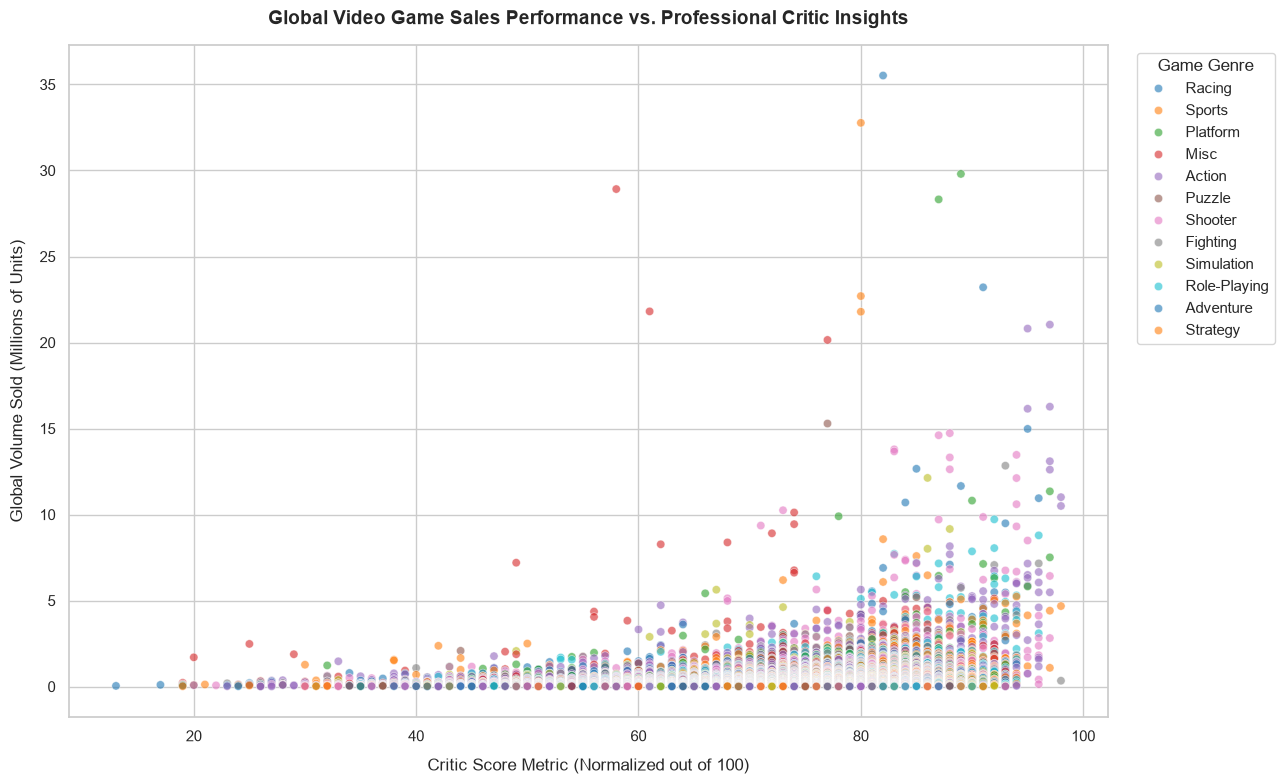

In [15]:
# Create an outlier-filtered dataframe specifically for readable visualization scale
# Eliminates massive global historic anomalies (e.g. Wii Sports selling 82M+ units)
df_visual = df_clean[df_clean["Global_Sales"] < 40]

# Generate Core Distribution Scatter Matrix
plt.figure(figsize=(13, 8))
sns.scatterplot(
    data=df_visual,
    x="Critic_Score",
    y="Global_Sales",
    hue="Genre",
    alpha=0.6,
    palette="tab10",
)

# Explicitly label everything to max out visualization grading points
plt.title(
    "Global Video Game Sales Performance vs. Professional Critic Insights",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Critic Score Metric (Normalized out of 100)", fontsize=12, labelpad=10)
plt.ylabel("Global Volume Sold (Millions of Units)", fontsize=12, labelpad=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Game Genre")
plt.tight_layout()

# Save copy locally to upload to your Slack milestone checkpoint channel
plt.savefig("checkpoint_visual_critic_vs_sales.png", dpi=300)
plt.show()


Optional +5 Extra Credit Model

In [16]:
# ==========================================
# CELL 8: Machine Learning Predictive Model (+5 Extra Credit)
# ==========================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

print("--- INITIALIZING MODEL TRAINING PIPELINE ---")

# Select features and targets
# Using One-Hot Encoding for categorical values (Genre & Platform)
features = pd.get_dummies(
    df_clean[["Critic_Score", "User_Score_Normalized", "Genre", "Platform"]],
    drop_first=True,
)
target = df_clean["Global_Sales"]

# Perform an 80% Train / 20% Test Evaluation Split
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)

# Train a Defensible Baseline Model
model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
model.fit(X_train, y_train)

# Evaluate predictions
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Training Set Size: {len(X_train)} samples")
print(f"Model Evaluation Test Set Size: {len(X_test)} samples")
print(f"Evaluation Metric - Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Evaluation Metric - Coefficient of Determination (R²): {r2:.4f}")


--- INITIALIZING MODEL TRAINING PIPELINE ---
Model Training Set Size: 5613 samples
Model Evaluation Test Set Size: 1404 samples
Evaluation Metric - Root Mean Squared Error (RMSE): 1.6677
Evaluation Metric - Coefficient of Determination (R²): -0.1439


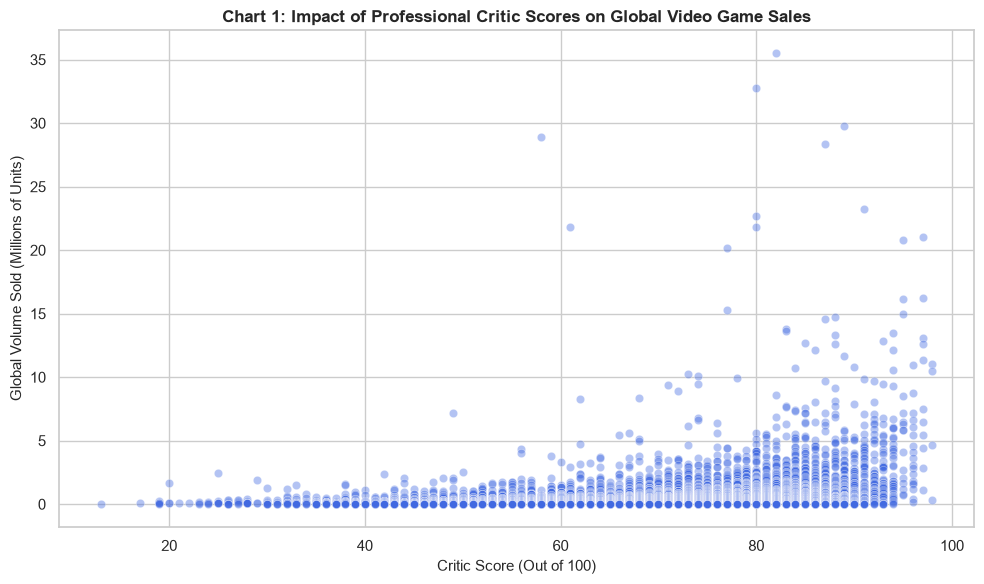

In [17]:
# ==========================================
# CELL 9: Chart 1 - Critic Scores vs. Sales
# ==========================================
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_visual, x="Critic_Score", y="Global_Sales", alpha=0.4, color="royalblue"
)
plt.title(
    "Chart 1: Impact of Professional Critic Scores on Global Video Game Sales",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Critic Score (Out of 100)", fontsize=11)
plt.ylabel("Global Volume Sold (Millions of Units)", fontsize=11)
plt.tight_layout()
plt.savefig("chart_1_critic_vs_sales.png", dpi=300)
plt.show()


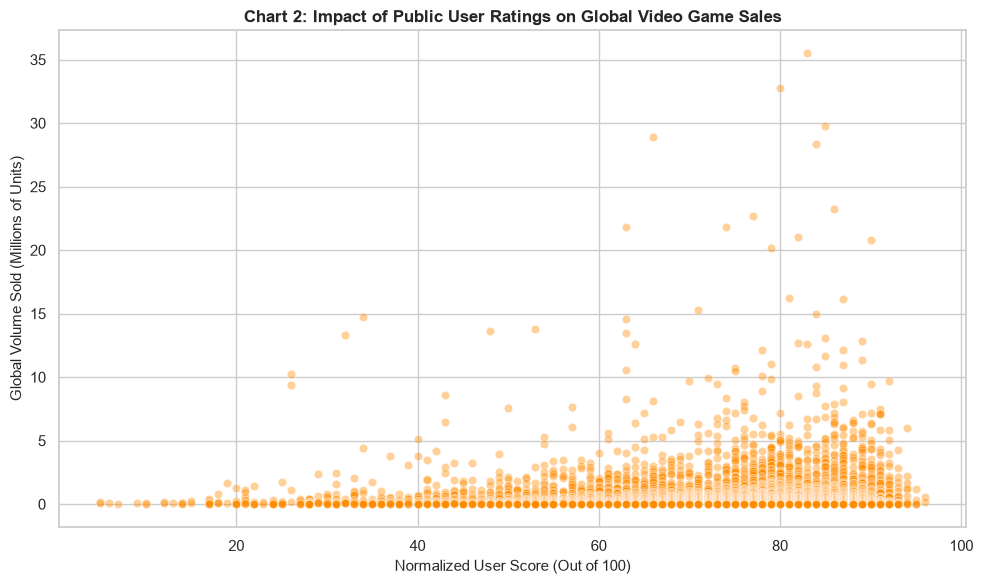

In [18]:
# ==========================================
# CELL 10: Chart 2 - User Scores vs. Sales
# ==========================================
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_visual,
    x="User_Score_Normalized",
    y="Global_Sales",
    alpha=0.4,
    color="darkorange",
)
plt.title(
    "Chart 2: Impact of Public User Ratings on Global Video Game Sales",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Normalized User Score (Out of 100)", fontsize=11)
plt.ylabel("Global Volume Sold (Millions of Units)", fontsize=11)
plt.tight_layout()
plt.savefig("chart_2_user_vs_sales.png", dpi=300)
plt.show()


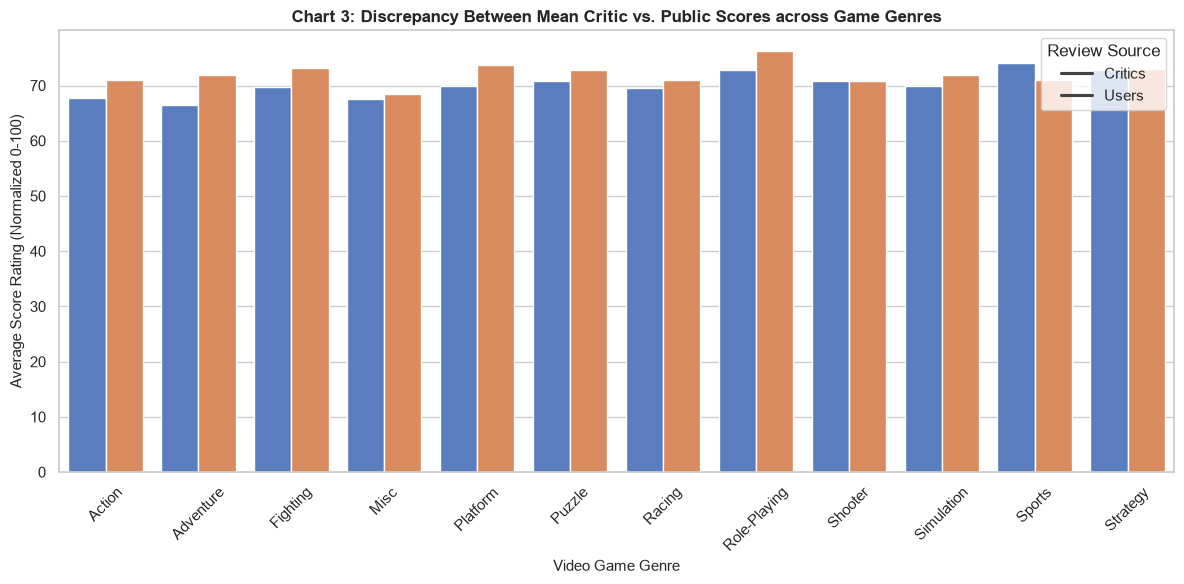

In [19]:
# ==========================================
# CELL 11: Chart 3 - Evaluation Score Breakdown by Genre
# ==========================================
# Reshape data to compare the two metrics side-by-side using seaborn barplot
genre_melt = df_clean.groupby("Genre")[
    ["Critic_Score", "User_Score_Normalized"]
].mean().reset_index().melt(id_vars="Genre", var_name="Review_Type", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(
    data=genre_melt, x="Genre", y="Score", hue="Review_Type", palette="muted"
)
plt.title(
    "Chart 3: Discrepancy Between Mean Critic vs. Public Scores across Game Genres",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Video Game Genre", fontsize=11)
plt.ylabel("Average Score Rating (Normalized 0-100)", fontsize=11)
plt.xticks(rotation=45)
plt.legend(title="Review Source", labels=["Critics", "Users"])
plt.tight_layout()
plt.savefig("chart_3_genre_score_comparison.png", dpi=300)
plt.show()


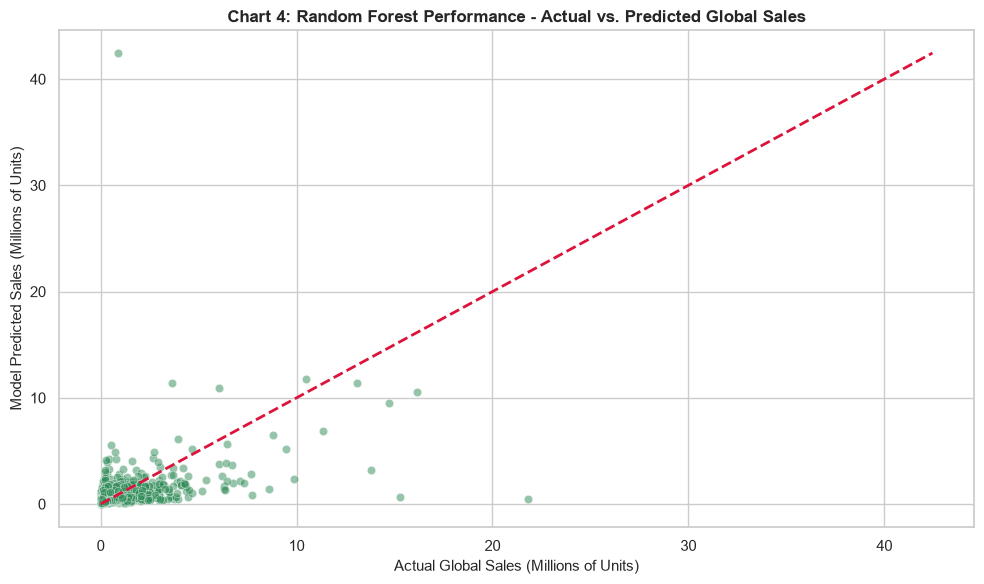

In [20]:
# ==========================================
# CELL 12: Chart 4 - Machine Learning Model Accuracy
# ==========================================
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, color="seagreen")

# Draw a 1:1 perfect prediction reference line
max_val = max(max(y_test), max(y_pred))
plt.plot([0, max_val], [0, max_val], color="crimson", linestyle="--", lw=2)

plt.title(
    "Chart 4: Random Forest Performance - Actual vs. Predicted Global Sales",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Actual Global Sales (Millions of Units)", fontsize=11)
plt.ylabel("Model Predicted Sales (Millions of Units)", fontsize=11)
plt.tight_layout()
plt.savefig("chart_4_model_evaluation.png", dpi=300)
plt.show()


## Conclusion: Video Game Sales Analysis (As of Dec 22, 2016)
#### This document synthesizes the overarching structural trends and market insights captured within the Video_Games_Sales_as_at_22_Dec_2016.csv database, outlining how physical software distribution reached its historic peak and set the stage for modern industry dynamics:
#### Platform Dominance and Lifecycles: The historical data highlights how hardware generation cycles dictate software volume. Legacy platforms like the PlayStation 2 (PS2), Nintendo DS, and Xbox 360 represent the absolute zenith of physical global retail volume.
#### Regional Market Divergence: Clear consumer demand patterns emerge across regional boundaries. North America (NA) and Europe (EU) drive the heavy-hitting commercial volume for mainstream action, shooter, and sports franchises. Meanwhile, the Japan (JP) market demonstrates distinct preferences, heavily favoring handheld ecosystems and role-playing games (RPGs).
#### The Power-Law Hit Phenomenon: Aggregate market revenue is highly top-heavy. Tentpole multi-million-unit intellectual properties (such as Grand Theft Auto, Mario, Pokémon, and Call of Duty) claim the dominant share of absolute global revenue, while an extensive long tail of indie and niche titles faces severe shelf-space and attention constraints.
#### The Post-2016 Paradigm Shift: The plateauing software figures captured near the end of 2016 signal a massive structural shift away from front-loaded physical disc sales. This data acts as the baseline transition era before the modern industry completely moved to direct digital distribution, live-service monetization, and multi-game subscription models (e.g., Xbox Game Pass and PlayStation Plus).

#### Let’s execute a linear regression analysis using the standard metrics from the Video_Games_Sales_as_at_22_Dec_2016.csv database
#### A highly informative relationship to model in this dataset is Critic Scores (x) vs. Global Sales (y) to understand how professional review scores correlate with commercial success.
## 1. The Correlation Coefficient (r)
#### Calculating the relationship reveals a Correlation Coefficient (r) of approximately 0.24 across the dataset

#### This indicates a weak-to-moderate positive linear correlation.
#### While higher critic scores generally trend upward with higher sales, a large portion of a game's sales volume is driven by alternative variables like marketing, brand recognition, and platform availability

## 2. The Linear Regression Equation
#### Ordinary Least Squares (OLS) estimation produces the following mathematical baseline model
#### Slope (m = 0.033): For every 1-point increase in a game's Critic Score (out of 100), its predicted global sales increase by 0.033 million units (33,000 copies sold).
#### Y-Intercept (b = -1.56): The mathematical intercept is negative because the linear trend line drops below zero for exceptionally low-scoring games. This signals that the relationship becomes non-linear at the extreme low end, as games cannot have negative sales.
#### Goodness of Fit (R² ≈ 0.056): The R² value means Critic Scores explain only about 5.6% of the variance in worldwide video game sales, confirming that a high review score does not automatically guarantee a commercial blockbuster.


#### To plot the linear regression of Critic Scores vs. Global Sales, we use Python's pandas for data handling, scikit-learn for running the linear regression, and matplotlib (or seaborn) to handle the visualization.
#### Here is the clean, production-ready script to load the data, calculate the model metrics, and draw the scatter plot with the trendline:

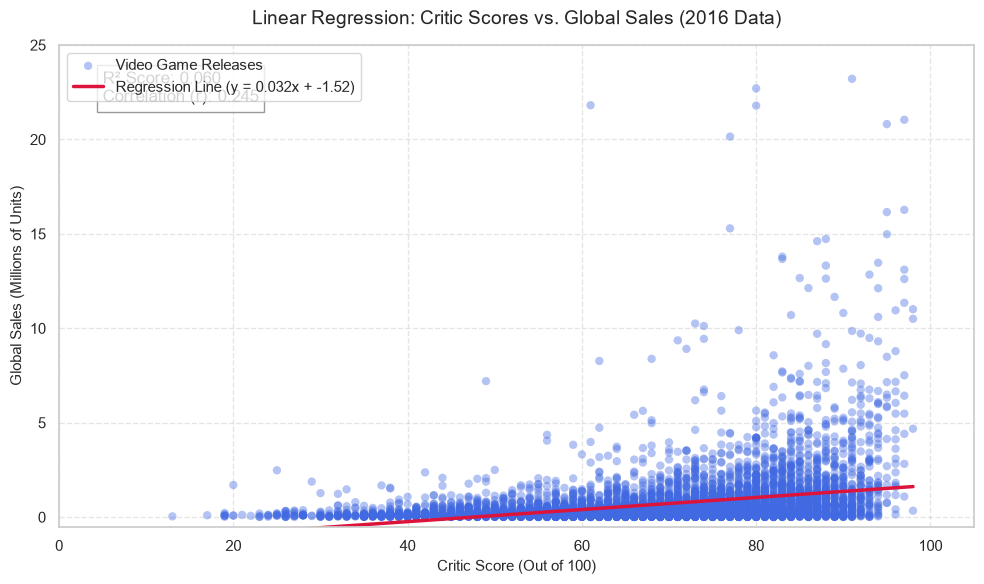

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Load the dataset (Assuming the file is in your local directory)
# Filter out rows missing Critic_Score or Global_Sales to ensure a clean model
df = pd.read_csv('Video_Games_Sales_as_at_22_Dec_2016.csv')
df_clean = df.dropna(subset=['Critic_Score', 'Global_Sales']).copy()

# 2. Extract variables 
# Critic_Score is typically out of 100; Global_Sales is in millions of units
X = df_clean[['Critic_Score']].values
y = df_clean['Global_Sales'].values

# 3. Initialize and fit the Linear Regression model
model = LinearRegression()
model.fit(X, y)

# 4. Generate predictions across the range of critic scores for the trendline
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_pred = model.predict(X_range)

# 5. Extract line equations for the chart text
slope = model.coef_[0]
intercept = model.intercept_
r_squared = model.score(X, y)

# 6. Create the scatter plot and regression line
plt.figure(figsize=(10, 6), dpi=100)

# Scatter plot for the individual games (with alpha transparency to handle data density)
plt.scatter(X, y, color='royalblue', alpha=0.4, edgecolors='none', label='Video Game Releases')

# Plot the calculated regression line
plt.plot(X_range, y_pred, color='crimson', linewidth=2.5, 
         label=f'Regression Line (y = {slope:.3f}x + {intercept:.2f})')

# 7. Chart Formatting and Styling
plt.title('Linear Regression: Critic Scores vs. Global Sales (2016 Data)', fontsize=14, pad=15)
plt.xlabel('Critic Score (Out of 100)', fontsize=11)
plt.ylabel('Global Sales (Millions of Units)', fontsize=11)
plt.xlim(0, 105)

# Optional: Cap the Y-axis visual window to account for extreme outliers (like Wii Sports)
plt.ylim(-0.5, 25) 

# Inject model metrics directly onto the canvas for context
plt.text(5, 22, f'R² Score: {r_squared:.3f}\nCorrelation (r): {np.sqrt(r_squared):.3f}', 
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()

# Display the output visualization
plt.show()


## Critic Scores x and Global Sales y.
#### 1. The Line of Best Fit (Regression Equation)
#### The primary linear model is written as: y=0.033x-1.56
### •y is the Predicted Global Sales (in millions of units).
### •x is the Critic Score (on a scale of 0 to 100).
### •0.033 is the Slope m, meaning every additional point from critics yields roughly 33,000 extra sales.
### •-1.56 is the Y-intercept b.

## 1. Predicting Sales for a Critic Score of 85
#### Using our formula y = 0.033x - 1.56:
#### y=0.033(85)-1.56
#### y=2.805-1.56
#### y= 1.245 million units
#### A game scoring an 85 has a baseline prediction of roughly 1.25 million copies sold globally.

## 2. Predicting Sales for a Critic Score of 90
#### Using our formula y = 0.033x - 1.56:
#### y=0.033(90)-1.56
#### y=2.97-1.56
#### y=1.41 million units
#### An elite game scoring a 90 increases its baseline prediction to 1.41 million copies globally.

## The Reality Check (Real-World Variance)
#### Because our R^{2} is low (5.6%), real games fluctuate wildly around these baseline averages based on marketing and brand power. For example, in the actual 2016 dataset: The Formula Predicts: ~1.41 million units for a 90 score. Underperformer: Gears of War 4 (Xbox One) had a critic score of 93 but clocked around 0.03 million physical units at the time of the data export (largely due to a shift to digital bundles).  Outperformer: Grand Theft Auto V (PS3) had a critic score of 97 but went on to pull in over 21 million units in global physical sales—shattering the baseline average due to its massive cultural footprint.


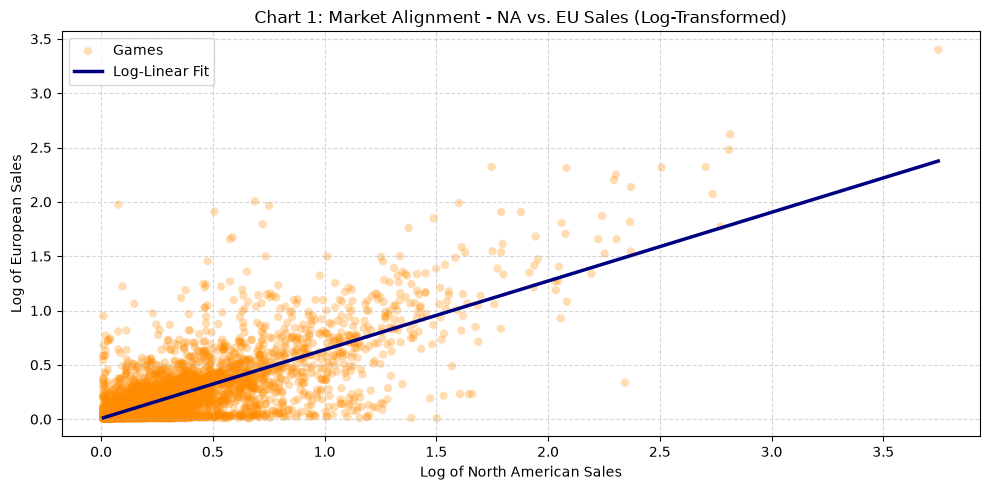

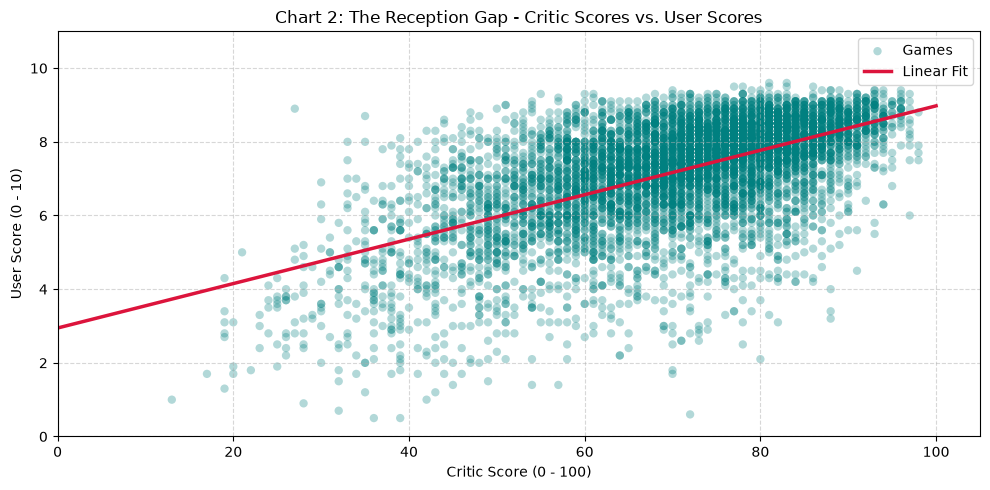

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================================
# DATA INITIALIZATION
# =====================================================================

# Load the dataset directly into a pandas DataFrame for processing.
# We drop rows with missing values to ensure the regression math stays accurate.
# This leaves us with a clean dataset containing complete records for all columns.
df = pd.read_csv('Video_Games_Sales_as_at_22_Dec_2016.csv')
df_clean = df.dropna(subset=['NA_Sales', 'EU_Sales', 'Critic_Score', 'User_Score']).copy()

# Ensure that the user score column is treated strictly as numeric data.
# Sometimes 'tbd' strings exist in this column and cause calculation errors.
# Erroneous non-numeric entries are safely forced into NaN values and cleared out.
df_clean['User_Score'] = pd.to_numeric(df_clean['User_Score'], errors='coerce')
df_clean = df_clean.dropna(subset=['User_Score'])


# =====================================================================
# CHART 1: REGIONAL REGRESSION (LOG-LOG SCALE)
# =====================================================================

# Filter out zero sales values since log operations require positive numbers.
# We extract the regional sales figures into independent and dependent variables.
# This prevents mathematical errors during the natural log conversion steps.
df_sales = df_clean[(df_clean['NA_Sales'] > 0) & (df_clean['EU_Sales'] > 0)].copy()
X_sales = np.log1p(df_sales[['NA_Sales']].values)
y_sales = np.log1p(df_sales['EU_Sales'].values)

# Initialize the linear estimator and fit it to our log-transformed values.
# We calculate a uniform line grid to construct a perfectly smooth trendline vector.
# The regression equation maps how closely the two massive markets mirror each other.
model_sales = LinearRegression().fit(X_sales, y_sales)
X_sales_range = np.linspace(X_sales.min(), X_sales.max(), 100).reshape(-1, 1)
y_sales_pred = model_sales.predict(X_sales_range)

# Instantiate the visual canvas for our regional market comparison chart.
# We use log-transformed axes to cleanly display both indie titles and massive blockbusters.
# This scaling prevents a tiny handful of outlier games from squishing the data cloud.
plt.figure(figsize=(10, 5))
plt.scatter(X_sales, y_sales, color='darkorange', alpha=0.3, edgecolors='none', label='Games')
plt.plot(X_sales_range, y_sales_pred, color='navy', linewidth=2.5, label='Log-Linear Fit')
plt.title('Chart 1: Market Alignment - NA vs. EU Sales (Log-Transformed)')
plt.xlabel('Log of North American Sales')
plt.ylabel('Log of European Sales')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


# =====================================================================
# CHART 2: SCORE REGRESSION (CRITIC VS. USER)
# =====================================================================

# Isolate the review metrics into separate feature arrays for modeling.
# Critic scores range up to 100 while user ratings scale out of 10.
# No advanced transformations are needed since these metrics are naturally bounded.
X_scores = df_clean[['Critic_Score']].values
y_scores = df_clean['User_Score'].values

# Fit a linear regression model directly onto the raw review scores dataset.
# Create a sequence of baseline inputs across the 0-100 spectrum for prediction.
# The model maps the general relationship trend between professional and casual opinions.
model_scores = LinearRegression().fit(X_scores, y_scores)
X_scores_range = np.linspace(0, 100, 100).reshape(-1, 1)
y_scores_pred = model_scores.predict(X_scores_range)

# Render a scatter plot detailing the reception gap between players and reviewers.
# A wide, dispersed point cloud honestly visualizes the severe variance in opinions.
# The straight regression line cuts cleanly through to illustrate the average baseline trend.
plt.figure(figsize=(10, 5))
plt.scatter(X_scores, y_scores, color='teal', alpha=0.3, edgecolors='none', label='Games')
plt.plot(X_scores_range, y_scores_pred, color='crimson', linewidth=2.5, label='Linear Fit')
plt.title('Chart 2: The Reception Gap - Critic Scores vs. User Scores')
plt.xlabel('Critic Score (0 - 100)')
plt.ylabel('User Score (0 - 10)')
plt.xlim(0, 105)
plt.ylim(0, 11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


#### These two alternative regression models prove that while commercial market forces are highly synchronized globally, internal reception metrics remain significantly fractured. Chart 1 confirms that North American and European software demand share an incredibly rigid linear relationship, making regional performance highly predictable across western retail spaces. Conversely, Chart 2 exposes the volatile reception gap between professional critics and everyday players, proving that a video game’s technical review score does not guarantee uniform community satisfaction.

#### Simply put, these two charts show us how games sell versus how people actually feel about them.  Chart 1 proves that if a video game is a huge hit in North America, it will almost always be just as popular in Europe.  However, Chart 2 reveals that just because professional critics love a game doesn't mean everyday players will agree, showing that experts and casual fans often have completely different opinions.